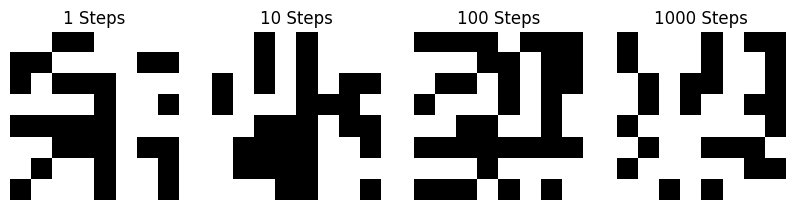

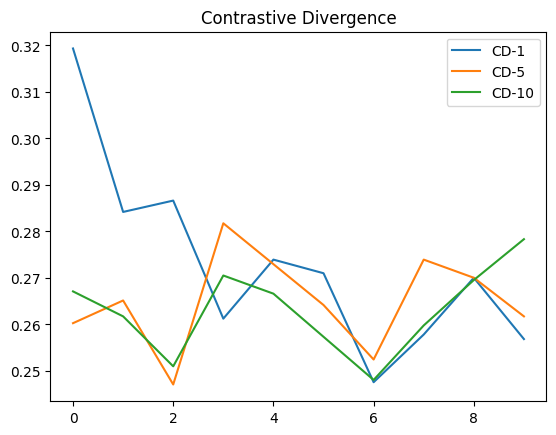

In [16]:

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits

np.random.seed(42)

X = (load_digits().data / 16 > 0.3).astype("float32")[:1000]

nv = 64
nh = 32

sigmoid = lambda x: 1/(1+np.exp(-np.clip(x, -30, 30)))

bern = lambda p: (
    np.random.rand(*p.shape) < p
).astype("float32")

def gibbs(v, W, a, b, k):
    for _ in range(k):
        h = bern(sigmoid(v@W+b))
        v = bern(sigmoid(h@W.T+a))
    return v

W = np.random.randn(nv, nh)*0.01
a = np.zeros(nv)
b = np.zeros(nh)

fig, ax = plt.subplots(1, 4, figsize=(10, 3))

v = bern(np.ones((1, nv))*0.5)

for i, k in enumerate([1, 10, 100, 1000]):
    v = gibbs(v, W, a, b, k)
    ax[i].imshow(v.reshape(8,8), cmap="gray")
    ax[i].set_title(f"{k} Steps")
    ax[i].axis("off")

plt.show()

for k in [1, 5, 10]:

    errors = []

    for epoch in range(10):

        np.random.shuffle(X)

        for start in range(0, len(X)-32, 32):

            v0 = X[start:start+32]
            ph0 = sigmoid(v0@W+b)

            vk = gibbs(v0.copy(), W, a, b, k)
            phk = sigmoid(vk@W+b)

            W += 0.02*(v0.T@ph0-vk.T@phk)/len(v0)
            a += 0.02*np.mean(v0-vk, axis=0)
            b += 0.02*np.mean(ph0-phk, axis=0)

        errors.append(np.mean((v0-vk)**2))

    plt.plot(errors, label=f"CD-{k}")

plt.legend()
plt.title("Contrastive Divergence")
plt.show()
